Python version: 3.11.9
TensorFlow version: 2.21.0
Current directory: C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project

Selected training directory: C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project\processed_train_images
Training CSV exists: True
Processed test directory exists: True

Number of classes: 10
Total training images: 10407


,Disease/Condition Class,Number of Images
0,bacterial_leaf_blight,479
1,bacterial_leaf_streak,380
2,bacterial_panicle_blight,337
3,blast,1738
4,brown_spot,965
5,dead_heart,1442
6,downy_mildew,620
7,hispa,1594
8,normal,1764
9,tungro,1088


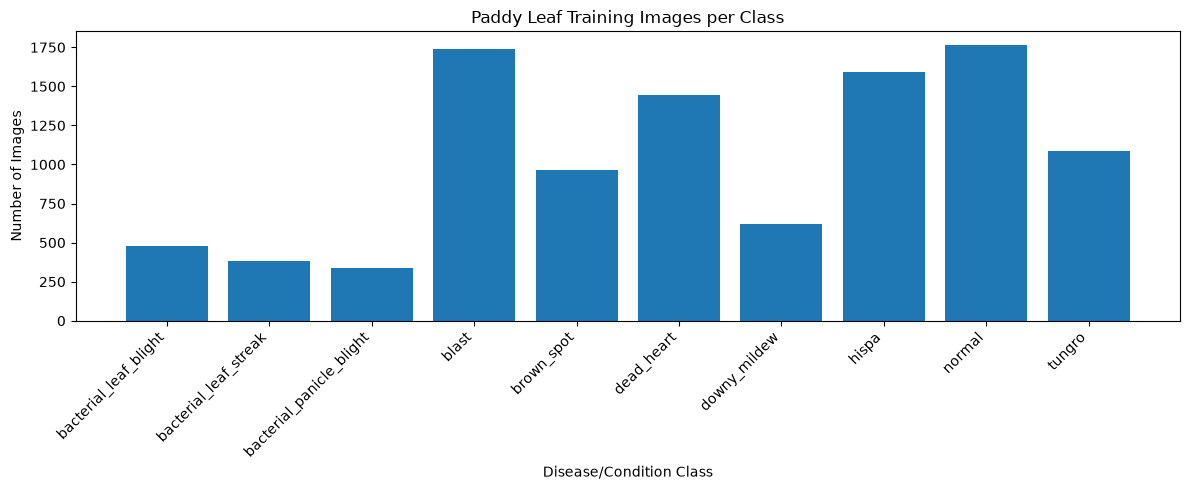


Sample image files:
bacterial_leaf_blight\bacterial_leaf_blight_00001.jpg
bacterial_leaf_blight\bacterial_leaf_blight_00002.jpg
bacterial_leaf_blight\bacterial_leaf_blight_00003.jpg
bacterial_leaf_blight\bacterial_leaf_blight_00004.jpg
bacterial_leaf_blight\bacterial_leaf_blight_00005.jpg


In [2]:
# Cell 1: Imports and Dataset Verification

import sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

print("Python version:", sys.version.split()[0])
print("TensorFlow version:", tf.__version__)
print("Current directory:", Path.cwd())

# Dataset directories
PROJECT_DIR = Path.cwd()
PROCESSED_TRAIN_DIR = PROJECT_DIR / "processed_train_images"
RAW_TRAIN_DIR = PROJECT_DIR / "train_images"
PROCESSED_TEST_DIR = PROJECT_DIR / "processed_test_images"
TRAIN_CSV = PROJECT_DIR / "train.csv"

# Prefer the preprocessed training images from Sprint 1.
if PROCESSED_TRAIN_DIR.exists():
    TRAIN_DIR = PROCESSED_TRAIN_DIR
elif RAW_TRAIN_DIR.exists():
    TRAIN_DIR = RAW_TRAIN_DIR
else:
    raise FileNotFoundError(
        "Cannot find processed_train_images or train_images. "
        "Check the project directory."
    )

print("\nSelected training directory:", TRAIN_DIR)
print("Training CSV exists:", TRAIN_CSV.exists())
print("Processed test directory exists:", PROCESSED_TEST_DIR.exists())

# Identify class folders and count images
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

class_folders = sorted(
    folder for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
)

if not class_folders:
    raise ValueError(
        f"No class subfolders found inside {TRAIN_DIR}"
    )

class_counts = {}

for folder in class_folders:
    count = sum(
        1 for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    )
    class_counts[folder.name] = count

class_names = list(class_counts.keys())

class_summary = pd.DataFrame({
    "Disease/Condition Class": class_names,
    "Number of Images": [class_counts[name] for name in class_names]
})

print("\nNumber of classes:", len(class_names))
print("Total training images:", sum(class_counts.values()))
display(class_summary)

# Visualize class distribution
plt.figure(figsize=(12, 5))
plt.bar(class_names, [class_counts[name] for name in class_names])
plt.title("Paddy Leaf Training Images per Class")
plt.xlabel("Disease/Condition Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Display sample image paths
sample_paths = [
    file
    for folder in class_folders
    for file in folder.iterdir()
    if file.is_file()
    and file.suffix.lower() in IMAGE_EXTENSIONS
][:5]

print("\nSample image files:")
for path in sample_paths:
    print(path.relative_to(TRAIN_DIR))

In [3]:
# Cell 2: Split Labeled Images into Training, Validation, and Evaluation Sets

from sklearn.model_selection import train_test_split

# Collect image paths and their class labels
image_records = []

for class_name in class_names:
    class_folder = TRAIN_DIR / class_name

    for image_path in class_folder.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            image_records.append({
                "image_path": str(image_path),
                "label": class_name
            })

image_df = pd.DataFrame(image_records)

# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    image_df,
    test_size=0.20,
    random_state=42,
    stratify=image_df["label"]
)

# Second split: divide the temporary data equally
val_df, eval_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

# Reset row indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
eval_df = eval_df.reset_index(drop=True)

print("Dataset split completed.")
print(f"Training images:   {len(train_df):,} ({len(train_df)/len(image_df):.1%})")
print(f"Validation images: {len(val_df):,} ({len(val_df)/len(image_df):.1%})")
print(f"Evaluation images: {len(eval_df):,} ({len(eval_df)/len(image_df):.1%})")
print(f"Total images:      {len(image_df):,}")

# Check that all classes are represented in each subset
split_summary = pd.DataFrame({
    "Class": class_names,
    "Training": [
        (train_df["label"] == c).sum() for c in class_names
    ],
    "Validation": [
        (val_df["label"] == c).sum() for c in class_names
    ],
    "Evaluation": [
        (eval_df["label"] == c).sum() for c in class_names
    ]
})

display(split_summary)

# Verify that no image path is shared between subsets
assert set(train_df["image_path"]).isdisjoint(val_df["image_path"])
assert set(train_df["image_path"]).isdisjoint(eval_df["image_path"])
assert set(val_df["image_path"]).isdisjoint(eval_df["image_path"])

print("Verification passed: no image paths overlap between subsets.")

Dataset split completed.
Training images:   8,325 (80.0%)
Validation images: 1,041 (10.0%)
Evaluation images: 1,041 (10.0%)
Total images:      10,407


,Class,Training,Validation,Evaluation
0,bacterial_leaf_blight,383,48,48
1,bacterial_leaf_streak,304,38,38
2,bacterial_panicle_blight,270,34,33
3,blast,1390,174,174
4,brown_spot,772,96,97
5,dead_heart,1154,144,144
6,downy_mildew,496,62,62
7,hispa,1275,159,160
8,normal,1411,177,176
9,tungro,870,109,109


Verification passed: no image paths overlap between subsets.


In [4]:
# Cell 3: Define Image Loading, Resizing, and Augmentation

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE

# Convert class names to numerical labels
class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

# Data augmentation is applied only to training images
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.2),
], name="data_augmentation")

def load_and_preprocess_image(image_path, label, training=False):
    # Read and decode the image
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image_bytes, channels=3)

    # Resize to the MobileNetV2 input dimensions
    image = tf.image.resize(image, IMAGE_SIZE)

    # Apply random transformations only to training data
    if training:
        image = data_augmentation(image, training=True)

    # MobileNetV2 preprocessing scales pixels to [-1, 1]
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label


def create_dataset(dataframe, training=False):
    image_paths = dataframe["image_path"].to_numpy()

    labels = dataframe["label"].map(class_to_index).to_numpy(
        dtype=np.int32
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 2000),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda path, label: load_and_preprocess_image(
            path, label, training
        ),
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


print("Image pipeline defined.")
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Augmentation: training data only")

Image pipeline defined.
Image size: (224, 224)
Batch size: 32
Number of classes: 10
Augmentation: training data only


Training batch image shape: (32, 224, 224, 3)
Training batch label shape: (32,)
Image value range: -1.0 to 1.0

Validation batches: 33
Evaluation batches: 33


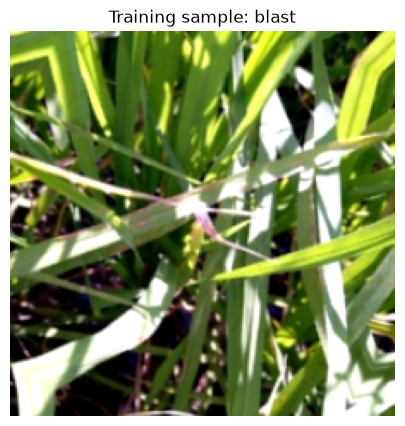

In [5]:
# Cell 4: Create Training, Validation, and Evaluation Pipelines

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df, training=False)
eval_ds = create_dataset(eval_df, training=False)

# Inspect one training batch
images, labels = next(iter(train_ds))

print("Training batch image shape:", images.shape)
print("Training batch label shape:", labels.shape)
print("Image value range:",
      float(tf.reduce_min(images)),
      "to",
      float(tf.reduce_max(images)))

print("\nValidation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Evaluation batches:", tf.data.experimental.cardinality(eval_ds).numpy())

# Display one preprocessed image for verification
plt.figure(figsize=(5, 5))

display_image = (images[0].numpy() + 1.0) / 2.0
display_image = np.clip(display_image, 0, 1)

plt.imshow(display_image)
plt.title(
    "Training sample: " +
    class_names[int(labels[0].numpy())]
)
plt.axis("off")
plt.show()

In [6]:
# Cell 5: Build the PalayCheck AI MobileNetV2 Model

from tensorflow.keras import layers, models

# Check available hardware
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus if gpus else "None detected; using CPU")

# Load the pretrained MobileNetV2 feature extractor
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers for initial transfer learning
base_model.trainable = False

# Build the classification model
inputs = layers.Input(shape=(224, 224, 3), name="leaf_image")

features = base_model(inputs, training=False)
features = layers.GlobalAveragePooling2D()(features)
features = layers.Dropout(0.25)(features)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="disease_predictions"
)(features)

model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="PalayCheckAI_MobileNetV2"
)

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Available GPUs: None detected; using CPU


Model: "PalayCheckAI_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ disease_predictions (Dense)          │ (None, 10)                  │          12,810 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
# Cell 6: Configure Training Callbacks

from pathlib import Path

MODEL_DIR = PROJECT_DIR / "model_outputs"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "palaycheck_mobilenetv2_best.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
]

print("Training callbacks configured.")
print("Best model will be saved to:", BEST_MODEL_PATH)

Training callbacks configured.
Best model will be saved to: C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project\model_outputs\palaycheck_mobilenetv2_best.keras


In [7]:
# Cell 7: Train MobileNetV2

EPOCHS = 5

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/5


C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 585ms/step - accuracy: 0.5474 - loss: 1.3240
Epoch 3: val_accuracy improved from 0.55524 to 0.57253, saving model to C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project\model_outputs\palaycheck_mobilenetv2_best.keras

Epoch 3: finished saving model to C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project\model_outputs\palaycheck_mobilenetv2_best.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 167s 641ms/step - accuracy: 0.5474 - loss: 1.3240 - val_accuracy: 0.5725 - val_loss: 1.2771 - learning_rate: 0.0010
Epoch 4/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 678ms/step - accuracy: 0.5745 - loss: 1.2621
Epoch 4: val_accuracy did not improve from 0.57253
261/261 ━━━━━━━━━━━━━━━━━━━━ 198s 760ms/step - accuracy: 0.5745 - loss: 1.2621 - val_accuracy: 0.5677 - val_loss: 1.2689 - learning_rate: 0.0010
Epoch 5/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 749ms/step - accuracy: 0.5876 - loss: 1.2123
Epoch 5: val_

In [9]:
# Cell 8: Evaluate the trained MobileNetV2 model

from pathlib import Path
import tensorflow as tf

MODEL_DIR = Path.cwd() / "model_outputs"
BEST_MODEL_PATH = MODEL_DIR / "palaycheck_mobilenetv2_best.keras"

print("Best model exists:", BEST_MODEL_PATH.exists())

if BEST_MODEL_PATH.exists():
    best_model = tf.keras.models.load_model(BEST_MODEL_PATH)
    print("\nLoaded best saved model.")
else:
    best_model = model
    print("\nUsing the model currently in memory.")

eval_results = best_model.evaluate(eval_ds, verbose=1)

print("\nEvaluation Results")
for metric_name, metric_value in zip(
    best_model.metrics_names, eval_results
):
    print(f"{metric_name}: {metric_value:.4f}")

Best model exists: True

Loaded best saved model.
33/33 ━━━━━━━━━━━━━━━━━━━━ 16s 412ms/step - accuracy: 0.7233 - loss: 0.8298

Evaluation Results
loss: 0.8298
compile_metrics: 0.7233


In [10]:
# Cell 9: Classification Report for MobileNetV2

import numpy as np
from sklearn.metrics import classification_report

# Recover the class names from the model's output layer
class_names = [
    "bacterial_leaf_blight",
    "bacterial_leaf_streak",
    "bacterial_panicle_blight",
    "blast",
    "brown_spot",
    "dead_heart",
    "downy_mildew",
    "hispa",
    "normal",
    "tungro"
]

# Collect the true labels from the evaluation dataset
y_true = np.concatenate([
    labels.numpy() for _, labels in eval_ds
])

# Predict the classes
y_prob = best_model.predict(eval_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Generate the classification report
print("Classification Report")
print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0,
        digits=4
    )
)

33/33 ━━━━━━━━━━━━━━━━━━━━ 15s 431ms/step
Classification Report
                          precision    recall  f1-score   support

   bacterial_leaf_blight     0.7407    0.4167    0.5333        48
   bacterial_leaf_streak     0.9583    0.6053    0.7419        38
bacterial_panicle_blight     0.8261    0.5758    0.6786        33
                   blast     0.7610    0.6954    0.7267       174
              brown_spot     0.5033    0.7938    0.6160        97
              dead_heart     0.9649    0.7639    0.8527       144
            downy_mildew     0.5694    0.6613    0.6119        62
                   hispa     0.8042    0.7188    0.7591       160
                  normal     0.8146    0.8239    0.8192       176
                  tungro     0.5541    0.7523    0.6381       109

                accuracy                         0.7233      1041
               macro avg     0.7497    0.6807    0.6978      1041
            weighted avg     0.7561    0.7233    0.7284      1041



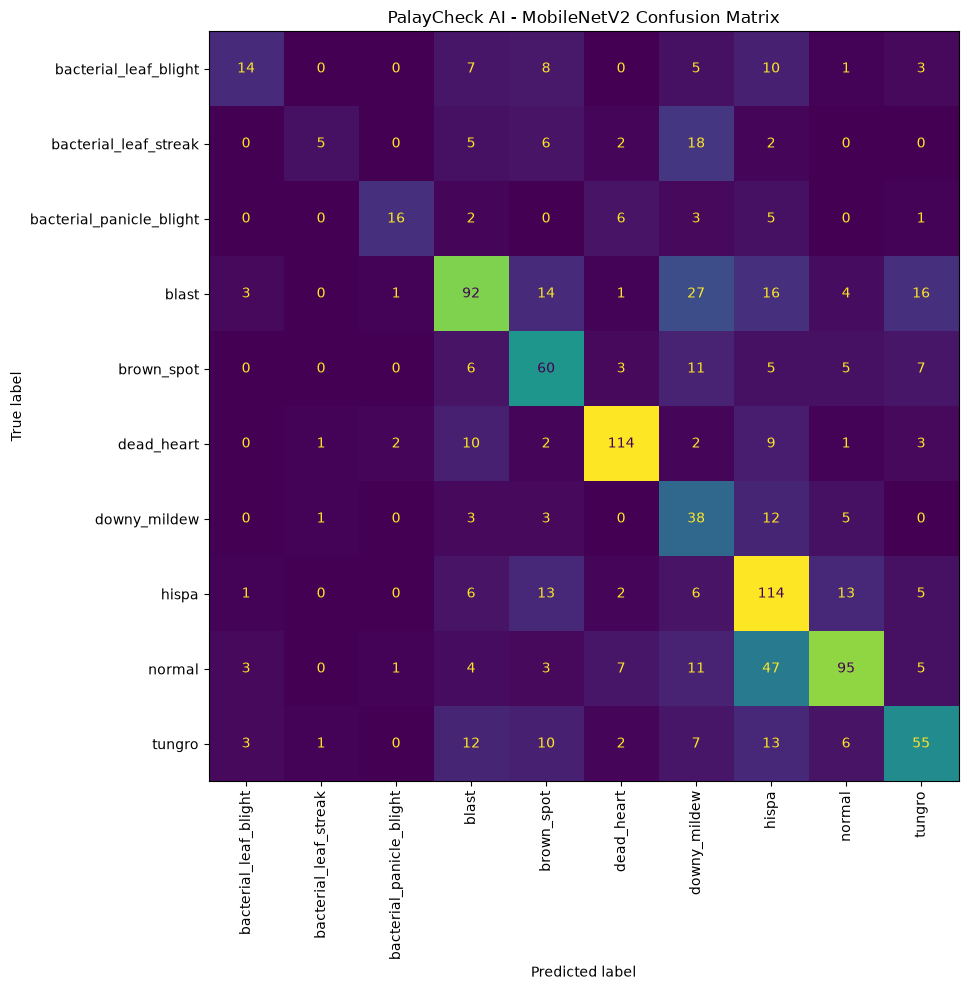

In [11]:
# Cell 10: Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

fig, ax = plt.subplots(figsize=(12, 10))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title("PalayCheck AI - MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

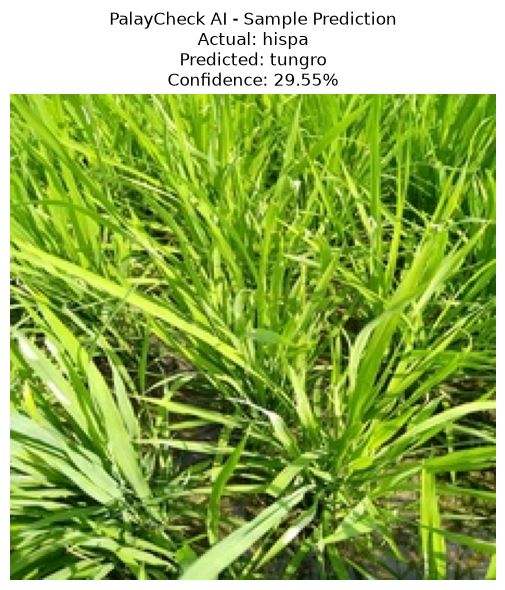

Actual class:      hispa
Predicted class:   tungro
Confidence score: 29.55%
Prediction result: INCORRECT


In [12]:
# Cell 11: Sample Paddy Leaf Prediction with Confidence Score

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Class names in the model's output order
class_names = [
    "bacterial_leaf_blight",
    "bacterial_leaf_streak",
    "bacterial_panicle_blight",
    "blast",
    "brown_spot",
    "dead_heart",
    "downy_mildew",
    "hispa",
    "normal",
    "tungro"
]

# Get one batch from the evaluation dataset
images, labels = next(iter(eval_ds))

# Select one sample image and its actual label
sample_image = images[0]
actual_index = int(labels[0].numpy())

# Predict the class
prediction = best_model.predict(
    tf.expand_dims(sample_image, axis=0),
    verbose=0
)[0]

predicted_index = int(np.argmax(prediction))
confidence = float(np.max(prediction)) * 100

# Convert image from [-1, 1] to [0, 1] for display
display_image = (sample_image.numpy() + 1.0) / 2.0
display_image = np.clip(display_image, 0, 1)

# Display the image and results
plt.figure(figsize=(6, 6))
plt.imshow(display_image)
plt.axis("off")
plt.title(
    f"PalayCheck AI - Sample Prediction\n"
    f"Actual: {class_names[actual_index]}\n"
    f"Predicted: {class_names[predicted_index]}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.tight_layout()
plt.show()

print("Actual class:     ", class_names[actual_index])
print("Predicted class:  ", class_names[predicted_index])
print(f"Confidence score: {confidence:.2f}%")
print(
    "Prediction result:",
    "CORRECT" if predicted_index == actual_index else "INCORRECT"
)

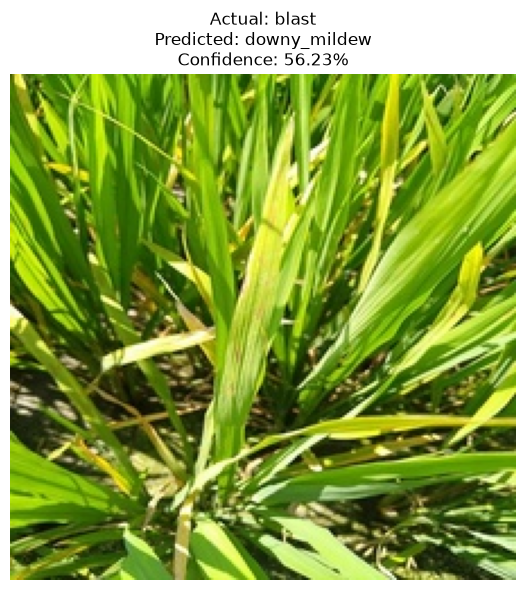

Image: blast_02189.jpg
Actual class: blast
Predicted class: downy_mildew
Confidence: 56.23%
Prediction result: INCORRECT


In [14]:
# Cell 12: Test Another Paddy Leaf Image from the Dataset

import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from PIL import Image

# Use the exact class order from the training label mapping
class_names = list(class_to_index.keys())

# Use the existing preprocessed dataset when available
dataset_dir = Path.cwd() / "processed_train_images"

if not dataset_dir.exists():
    dataset_dir = Path.cwd() / "train_images"

# Select a class folder and a sample image
class_dirs = sorted(
    folder for folder in dataset_dir.iterdir()
    if folder.is_dir()
)

selected_class = random.choice(class_dirs)

image_files = sorted(
    path for path in selected_class.iterdir()
    if path.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

if not image_files:
    raise FileNotFoundError(
        f"No images found in {selected_class}"
    )

image_path = random.choice(image_files)

# Load and resize the image
img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

image_array = np.array(
    img_resized,
    dtype=np.float32
)

# IMPORTANT: Apply the same preprocessing used during training
image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    image_array
)

# Create the batch expected by the model
image_batch = np.expand_dims(image_array, axis=0)

# Predict using the trained model
prediction_scores = best_model.predict(
    image_batch,
    verbose=0
)[0]

predicted_index = int(np.argmax(prediction_scores))
predicted_class = class_names[predicted_index]
confidence = float(prediction_scores[predicted_index]) * 100

# Display the image and prediction
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Actual: {selected_class.name}\n"
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.tight_layout()
plt.show()

print("Image:", image_path.name)
print("Actual class:", selected_class.name)
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")
print(
    "Prediction result:",
    "CORRECT" if predicted_class == selected_class.name
    else "INCORRECT"
)

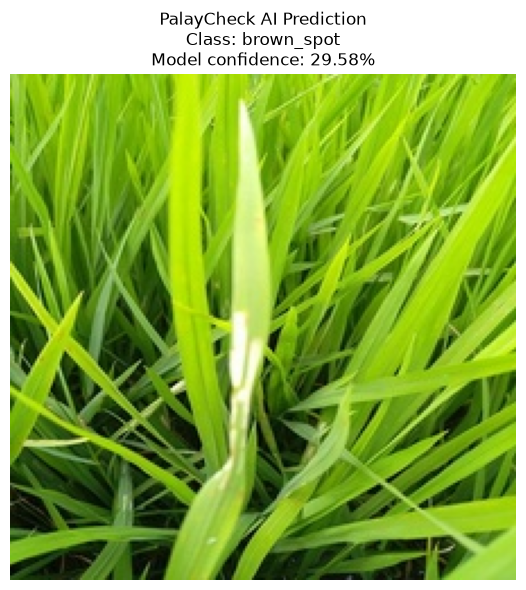

Selected image: hispa_05997.jpg
Predicted class: brown_spot
Confidence score: 29.58%
Note: This is a model prediction, not a confirmed diagnosis.


In [18]:
# Cell 13: Upload and Classify a Paddy Leaf Image

from pathlib import Path
from tkinter import Tk, filedialog
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Load the saved best model
MODEL_PATH = Path.cwd() / "model_outputs" / "palaycheck_mobilenetv2_best.keras"

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Saved model not found: {MODEL_PATH}")

upload_model = tf.keras.models.load_model(MODEL_PATH)

# Preserve the class-to-index mapping used during training
if "class_to_index" in globals():
    upload_class_names = [
        name for name, index in sorted(
            class_to_index.items(),
            key=lambda item: item[1]
        )
    ]
elif "train_ds" in globals() and hasattr(train_ds, "class_names"):
    upload_class_names = list(train_ds.class_names)
else:
    raise NameError(
        "Cannot find the training class mapping. "
        "Run the notebook's dataset setup cells first."
    )

if upload_model.output_shape[-1] != len(upload_class_names):
    raise ValueError(
        f"Model outputs {upload_model.output_shape[-1]} classes, "
        f"but the mapping contains {len(upload_class_names)} classes."
    )

# Open a file picker
root = Tk()
root.withdraw()
root.attributes("-topmost", True)

try:
    selected_file = filedialog.askopenfilename(
        title="Select a Paddy Leaf Image",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp"),
            ("All files", "*.*")
        ]
    )
finally:
    root.destroy()

if not selected_file:
    print("No image selected. Run this cell again to choose an image.")
else:
    # Validate and preprocess the selected image
    try:
        with Image.open(selected_file) as source:
            img = source.convert("RGB")

        display_img = img.copy()
        resized_img = img.resize((224, 224))

        image_array = np.asarray(
            resized_img,
            dtype=np.float32
        )

        image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
            image_array
        )

        image_batch = np.expand_dims(image_array, axis=0)

        # Predict the class
        scores = upload_model.predict(image_batch, verbose=0)[0]
        predicted_index = int(np.argmax(scores))
        predicted_class = upload_class_names[predicted_index]
        confidence = float(scores[predicted_index]) * 100

        # Display the result
        plt.figure(figsize=(7, 6))
        plt.imshow(display_img)
        plt.axis("off")
        plt.title(
            f"PalayCheck AI Prediction\n"
            f"Class: {predicted_class}\n"
            f"Model confidence: {confidence:.2f}%"
        )
        plt.tight_layout()
        plt.show()

        print("Selected image:", Path(selected_file).name)
        print("Predicted class:", predicted_class)
        print(f"Confidence score: {confidence:.2f}%")
        print(
            "Note: This is a model prediction, "
            "not a confirmed diagnosis."
        )

    except Exception as error:
        print("Could not process this image:", error)

In [20]:
# Cell 14: Fine-Tune MobileNetV2 and Compare Results

from pathlib import Path
import tensorflow as tf

# Confirm that the required dataset pipelines and saved model exist
MODEL_DIR = Path.cwd() / "model_outputs"
BEST_MODEL_PATH = MODEL_DIR / "palaycheck_mobilenetv2_best.keras"
FINETUNED_MODEL_PATH = MODEL_DIR / "palaycheck_mobilenetv2_finetuned.keras"

if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Current saved model not found: {BEST_MODEL_PATH}"
    )

print("Loading the current best model...")
baseline_model = tf.keras.models.load_model(BEST_MODEL_PATH)

# Measure the current model's validation accuracy
baseline_results = baseline_model.evaluate(
    val_ds,
    verbose=1,
    return_dict=True
)
baseline_accuracy = baseline_results["accuracy"]

print(f"\nCurrent validation accuracy: {baseline_accuracy:.4f}")

# Load a separate copy for fine-tuning
fine_tune_model = tf.keras.models.load_model(BEST_MODEL_PATH)

# Find the MobileNetV2 feature extractor inside the model
nested_models = [
    layer for layer in fine_tune_model.layers
    if isinstance(layer, tf.keras.Model)
]

if not nested_models:
    raise ValueError(
        "Could not find the MobileNetV2 feature extractor "
        "inside the saved model."
    )

mobilenet_base = nested_models[0]
mobilenet_base.trainable = True

# Fine-tune only the final 30 layers.
# Keep Batch Normalization layers frozen for stability.
for layer in mobilenet_base.layers[:-30]:
    layer.trainable = False

for layer in mobilenet_base.layers[-30:]:
    layer.trainable = not isinstance(
        layer, tf.keras.layers.BatchNormalization
    )

trainable_count = sum(
    int(layer.trainable)
    for layer in mobilenet_base.layers
)

print("Feature extractor:", mobilenet_base.name)
print("Trainable MobileNetV2 layers:", trainable_count)

# Recompile using a small learning rate
fine_tune_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the fine-tuned model separately so the original is protected
fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(FINETUNED_MODEL_PATH),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

# Fine-tune for up to five additional epochs
fine_tune_history = fine_tune_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=fine_tune_callbacks,
    verbose=1
)

# Load the best fine-tuned checkpoint and compare validation accuracy
if not FINETUNED_MODEL_PATH.exists():
    raise FileNotFoundError(
        "Fine-tuned checkpoint was not created. "
        "Check the training output for errors."
    )

fine_tuned_best = tf.keras.models.load_model(
    FINETUNED_MODEL_PATH
)

fine_tuned_results = fine_tuned_best.evaluate(
    val_ds,
    verbose=1,
    return_dict=True
)
fine_tuned_accuracy = fine_tuned_results["accuracy"]

print("\n" + "=" * 45)
print("MODEL COMPARISON")
print("=" * 45)
print(f"Original validation accuracy:   {baseline_accuracy:.4f}")
print(f"Fine-tuned validation accuracy: {fine_tuned_accuracy:.4f}")
print(
    f"Difference:                     "
    f"{fine_tuned_accuracy - baseline_accuracy:+.4f}"
)

# Replace the app's model only if validation accuracy improves
if fine_tuned_accuracy > baseline_accuracy:
    fine_tuned_best.save(BEST_MODEL_PATH)
    print("\nImprovement detected!")
    print("The app's saved model has been updated.")
else:
    print("\nNo validation accuracy improvement.")
    print("The original best model has been kept.")

print("\nOriginal model path:", BEST_MODEL_PATH)
print("Fine-tuned comparison model:", FINETUNED_MODEL_PATH)

Loading the current best model...
33/33 ━━━━━━━━━━━━━━━━━━━━ 20s 477ms/step - accuracy: 0.7003 - loss: 0.9139

Current validation accuracy: 0.7003
Feature extractor: mobilenetv2_1.00_224
Trainable MobileNetV2 layers: 19
Epoch 1/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 536ms/step - accuracy: 0.7206 - loss: 0.8348
Epoch 1: val_accuracy improved from None to 0.70893, saving model to C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project\model_outputs\palaycheck_mobilenetv2_finetuned.keras

Epoch 1: finished saving model to C:\Users\LVan\Desktop\MAPUA\4th Year\Introduction to Artificial Intelligence (CPE126-4)\Project\model_outputs\palaycheck_mobilenetv2_finetuned.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 164s 598ms/step - accuracy: 0.7206 - loss: 0.8348 - val_accuracy: 0.7089 - val_loss: 0.9070 - learning_rate: 1.0000e-05
Epoch 2/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 783ms/step - accuracy: 0.7379 - loss: 0.7939
Epoch 2: val_accuracy improved from 0.70893 to 0.71182,

FINAL MODEL EVALUATION
Validation Accuracy: 73.87%

Classification Report:
                          precision    recall  f1-score   support

   bacterial_leaf_blight     0.5758    0.3958    0.4691        48
   bacterial_leaf_streak     0.9643    0.7105    0.8182        38
bacterial_panicle_blight     0.8800    0.6471    0.7458        34
                   blast     0.7843    0.6897    0.7339       174
              brown_spot     0.5580    0.8021    0.6581        96
              dead_heart     0.9381    0.7361    0.8249       144
            downy_mildew     0.5921    0.7258    0.6522        62
                   hispa     0.7770    0.7233    0.7492       159
                  normal     0.8506    0.8362    0.8433       177
                  tungro     0.5882    0.8257    0.6870       109

                accuracy                         0.7387      1041
               macro avg     0.7508    0.7092    0.7182      1041
            weighted avg     0.7630    0.7387    0.7419      1041

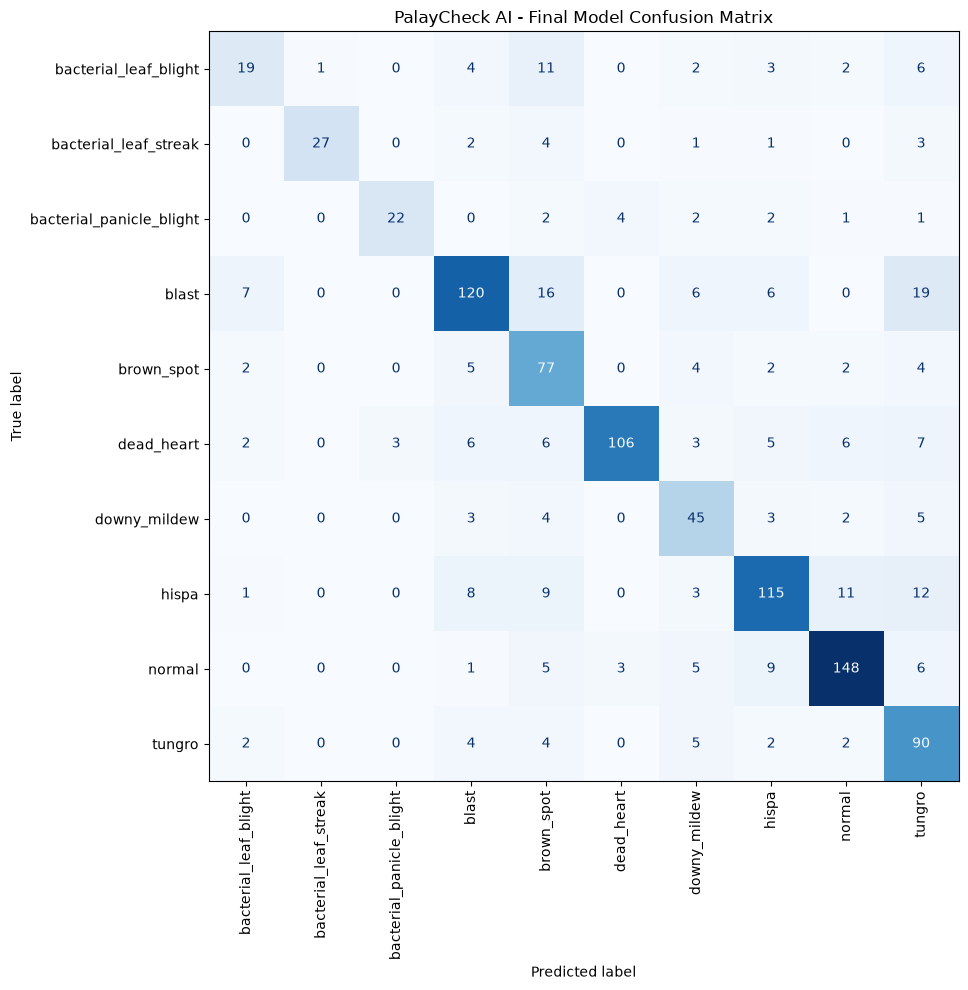

In [11]:
# Final Model Evaluation: Precision, Recall, F1-Score, and Confusion Matrix

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)
from pathlib import Path

# Load the final saved model
MODEL_PATH = Path.cwd() / "model_outputs" / "palaycheck_mobilenetv2_best.keras"

final_model = tf.keras.models.load_model(MODEL_PATH)

# Preserve the class order used during training
class_names = [
    name
    for name, index in sorted(
        class_to_index.items(),
        key=lambda item: item[1]
    )
]

y_true = []
y_pred = []

# Evaluate the model on the validation dataset
for images, labels in val_ds:
    probabilities = final_model.predict(images, verbose=0)

    label_array = labels.numpy()

    # Support both integer labels and one-hot encoded labels
    if label_array.ndim > 1 and label_array.shape[-1] > 1:
        batch_true = np.argmax(label_array, axis=1)
    else:
        batch_true = label_array.reshape(-1).astype(int)

    batch_pred = np.argmax(probabilities, axis=1)

    y_true.extend(batch_true.tolist())
    y_pred.extend(batch_pred.tolist())

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)

print("FINAL MODEL EVALUATION")
print("=" * 55)
print(f"Validation Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
        digits=4
    )
)

# Generate the confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
display.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)
plt.title("PalayCheck AI - Final Model Confusion Matrix")
plt.tight_layout()
plt.show()